In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
import tifffile

In [3]:
movie = tifffile.imread("./dendrites_rect_filtered.tif")
movie.shape

(19999, 55, 53)

In [4]:
%matplotlib inline

In [5]:
Y = np.load("./Y.npy")

In [6]:
Y.shape

(2915, 10000)

In [7]:
Y

array([[0.00000e+00, 0.00000e+00, 9.00000e-01, ..., 5.60000e+00,
        2.80000e+01, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 2.46600e+02,
        2.36950e+02, 0.00000e+00],
       [4.95000e+00, 4.95000e+00, 4.95000e+00, ..., 1.66400e+02,
        1.43700e+02, 0.00000e+00],
       ...,
       [2.42315e+03, 2.42315e+03, 2.42315e+03, ..., 2.07930e+03,
        3.17930e+03, 0.00000e+00],
       [1.87645e+03, 2.05190e+03, 2.10095e+03, ..., 2.58230e+03,
        2.50565e+03, 0.00000e+00],
       [1.33820e+03, 1.33820e+03, 1.28915e+03, ..., 1.37780e+03,
        1.33485e+03, 0.00000e+00]], dtype=float32)

In [8]:
Y.shape
Y = Y[:, :-1]

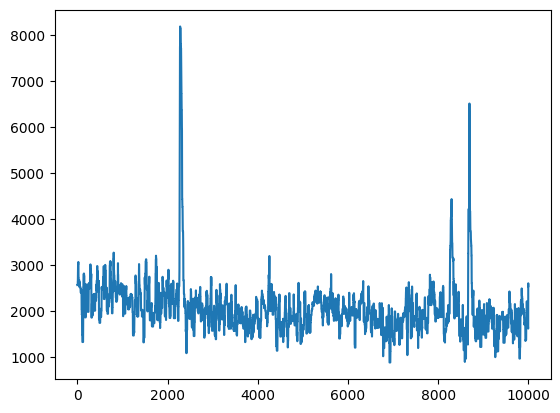

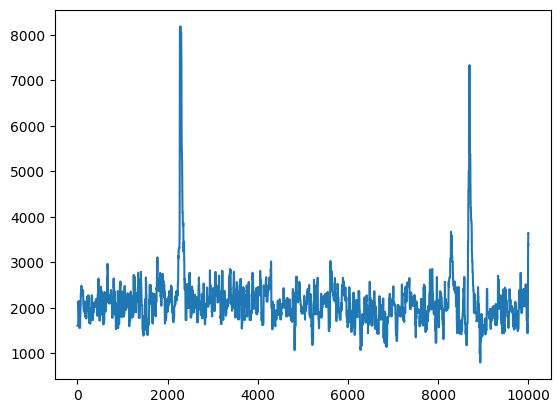

NameError: name 'projections' is not defined

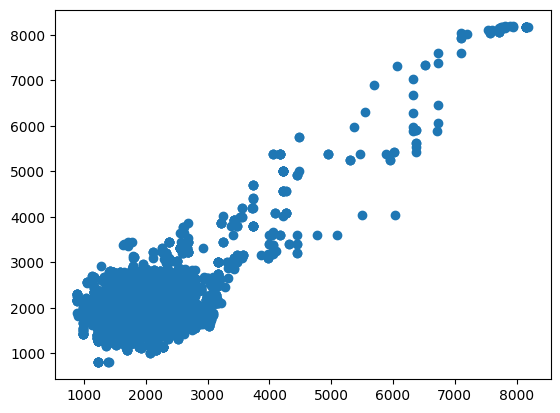

In [9]:
i1 = 1202
i2 = 1203

plt.plot(Y[i1, :])
plt.show()
plt.plot(Y[i2, :])
plt.show()

plt.scatter(Y[i1, :], Y[i2, :])
plt.scatter(projections[:, 0], projections[:, 1])

# IDEA FROM PHILIPPO, ONLY CONSIDER TOP 10 PERCENTILE OF PIXEL INTENSITY VALUES (times series vals), i.e. the upper cloud to remove the big bottom left cloud

In [10]:
Y = Y.astype(np.float64)
n = Y.shape[1]
i = i1
j = i2
yyt = Y @ Y.T
ysum = np.sum(Y, axis=1)
(yyt[i, j] - 1 / n * ysum[i] * ysum[j]) / (yyt[i, i] - 1 / n * ysum[i]**2)

np.float64(0.6813455892406317)

In [21]:
Y.shape[1]

9999

In [18]:
from numba import guvectorize, float64, int64, float32
from itertools import product

In [348]:
X.shape

(9999, 2)

In [349]:
v1.shape

(2,)

In [350]:
projections.shape

(9999, 2)

In [351]:
orthogonal_distances.shape

(9999, 2)

In [353]:
yyt.shape

(2915, 2915)

In [354]:
ysum.shape

(2915,)

In [23]:
@guvectorize([(float64[:, :], float64[:, :], float64[:], float64[:, :], float64[:, :], float64[:, :], float64[:], float64[:, :])], "(p, t), (t, n), (n), (t, n), (t, n), (p, p), (p)->(p, p)", target="parallel")
def corr_vec(Y: np.ndarray, X: np.ndarray, v1: np.array, projections: np.ndarray, orthogonal_distances: np.ndarray, yyt: np.ndarray, ysum: np.ndarray, matrix: np.ndarray):
    for i in range(yyt.shape[0]):
        for j in range(yyt.shape[0]):
            m = (yyt[i, j] - 1 / Y.shape[1] * ysum[i] * ysum[j]) / (yyt[i, i] - 1 / Y.shape[1] * ysum[i]**2)

            v1[0] = m
            v1[1] = 1.0

            x = Y[i, :]
            y = Y[j, :]
            
            # Step 1: Calculate means of x and y
            x_mean = np.mean(x)
            y_mean = np.mean(y)
            
            v1[0] += x_mean
            v1[1] += y_mean

            # denom = np.sqrt(v1.sum())
            # v1[0] = v1[0] / denom
            # v1[1] = v1[1] / denom

            v1 /= np.sqrt(np.sum(v1**2))
            
            X[:, 0] = x
            X[:, 1] = y
            projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
            orthogonal_distances = X - projections  # Euclidean distances
            s = 0
            for r in range(X.shape[0]):
                s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
            orthogonal_distances = orthogonal_distances**2
            
            # # Sum of orthogonal distances
            # # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
            matrix[i, j] = s / X.shape[0]
            
            # Sum of orthogonal distances
            # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
            # matrix[i, j] = sum_of_distances

In [24]:
matrix = np.zeros((Y.shape[0], Y.shape[0]))

In [29]:
corr_vec(Y, X, v1, projections, orthogonal_distances, yyt, ysum, matrix)

array([[1.16401809e-15, 6.36275179e+00, 6.26430365e+00, ...,
        8.25634066e+00, 6.52775840e+00, 5.72981173e+00],
       [7.10135526e+00, 5.06406244e-15, 2.18099402e+01, ...,
        1.87209997e+01, 1.88312062e+01, 1.89623513e+01],
       [6.85284492e+00, 2.23336840e+01, 7.64298523e-15, ...,
        3.24256003e+01, 3.21595342e+01, 3.24972144e+01],
       ...,
       [6.47277778e+00, 1.99382573e+01, 3.20679569e+01, ...,
        4.75498678e-13, 2.70217057e+02, 2.95138406e+02],
       [6.52607817e+00, 1.99134368e+01, 3.20143729e+01, ...,
        2.70211728e+02, 4.73633472e-13, 2.49883039e+02],
       [6.50939988e+00, 1.94146600e+01, 3.26675440e+01, ...,
        2.95156901e+02, 2.49908879e+02, 2.76130758e-13]])

In [26]:
Y = Y.astype(np.float64)
# n = Y.shape[1]
i = i1
j = i2
yyt = Y @ Y.T
ysum = np.sum(Y, axis=1)

In [14]:
ms = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float64)
corr_vec(yyt, ysum, ms)

array([[ 1.00000000e+00,  1.35527948e-02,  1.80612519e-01, ...,
         3.88027593e+00,  1.00591787e+00, -4.63753654e-01],
       [ 2.08789514e-03,  1.00000000e+00, -1.60653735e-01, ...,
        -2.91027727e+00, -2.45409604e+00, -2.96967944e-01],
       [ 1.06351286e-02, -6.14053067e-02,  1.00000000e+00, ...,
         2.29253733e+00,  1.56976882e+00,  3.88769243e-01],
       ...,
       [ 3.61818008e-04, -1.76149784e-03,  3.63035493e-03, ...,
         1.00000000e+00,  6.30442346e-01,  1.41204471e-01],
       [ 1.64072774e-04, -2.59827869e-03,  4.34825293e-03, ...,
         1.10278743e+00,  1.00000000e+00,  2.52767720e-01],
       [-2.75078551e-04, -1.14340250e-03,  3.91621374e-03, ...,
         8.98235600e-01,  9.19214778e-01,  1.00000000e+00]])

In [288]:
x = Y[i1, :]
y = Y[i2, :]

# Step 1: Calculate means of x and y
x_mean = np.mean(x)
y_mean = np.mean(y)

# Step 2: Calculate slope (m) using inner products
m = (np.dot(x, y) - n * x_mean * y_mean) / (np.dot(x, x) - n * x_mean**2)

v1 = np.array([m, 1])
v1[0] += x_mean
v1[1] += y_mean

v1 = v1 / np.sqrt(np.sum(v1**2))

X = np.column_stack([x, y])
projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
# orthogonal_distances = orthogonal_distances**2

# Sum of orthogonal distances
sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
# print("Sum of orthogonal distances:", sum_of_distances)

In [28]:
orthogonal_distances = X - projections

In [290]:
X.shape

(9999, 2)

In [291]:
projections.shape

(9999, 2)

In [296]:
(X - projections)[]

array([[-5.68434189e-14, -5.68434189e-14],
       [-5.68434189e-14, -5.68434189e-14],
       [-5.68434189e-14, -5.68434189e-14],
       ...,
       [ 0.00000000e+00,  0.00000000e+00],
       [-5.68434189e-14, -5.68434189e-14],
       [-5.68434189e-14, -5.68434189e-14]])

In [294]:
orthogonal_distances

array([8.03887339e-14, 8.03887339e-14, 8.03887339e-14, ...,
       0.00000000e+00, 8.03887339e-14, 8.03887339e-14])

In [289]:
orthogonal_distances.shape

(9999,)

In [16]:
from tqdm import tqdm

In [340]:
corr_matrix = np.zeros(ms.shape, dtype=np.float64)

for i in tqdm(range(yyt.shape[0])):
    for j in range(yyt.shape[0]):
        v1 = np.array([ms[i, j], 1])

        x = Y[i, :]
        y = Y[j, :]
        
        # Step 1: Calculate means of x and y
        x_mean = np.mean(x)
        y_mean = np.mean(y)
        
        v1[0] += x_mean
        v1[1] += y_mean
        
        v1 = v1 / np.sqrt(np.sum(v1**2))
        
        X = np.column_stack([x, y])
        projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
        # orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
        orthogonal_distances = ((X - projections)**2)
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
        # orthogonal_distances = orthogonal_distances**2
        
        # Sum of orthogonal distances
        # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
        corr_matrix[i, j] = s / X.shape[0]

  0%|                                                                                                                                               | 0/2915 [00:05<?, ?it/s]


KeyboardInterrupt: 

In [188]:
%load_ext viztracer

In [12]:
i1 = 130
i2 = 132

x = Y[i1, :]
y = Y[i2, :]

# Step 1: Calculate means of x and y
x_mean = np.mean(x)
y_mean = np.mean(y)

v1 = np.array([ms[i1, i2], 1])
v1[0] += x_mean
v1[1] += y_mean

In [13]:
v1 /= np.sqrt(np.sum(v1**2))

In [14]:
X = np.column_stack([x, y])

In [15]:
projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1

In [16]:
orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances

In [321]:
X.shape

(9999, 2)

In [322]:
projections.shape

(9999, 2)

In [323]:
orthogonal_distances.shape

(9999,)

In [325]:
orthogonal_distances

array([246.76469782, 246.76469782, 246.76469782, ...,  76.39452837,
        30.75888703,  44.66578213])

In [337]:
s = np.float64(0)
for r in range(X.shape[0]):
    s += np.sqrt((X - projections)[r, 0]**2 + (X - projections)[r, 1]**2)

In [338]:
s

np.float64(984638.7810667086)

In [339]:
orthogonal_distances.sum() - s

np.float64(2.6775524020195007e-09)

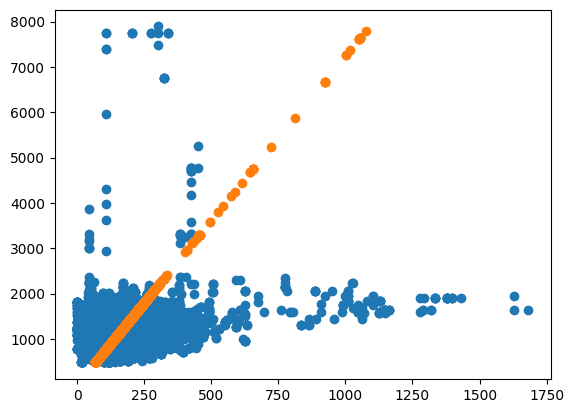

In [324]:
plt.scatter(Y[i1, :], Y[i2, :])
plt.scatter(projections[:, 0], projections[:, 1])

In [11]:
ms = np.load("./corr_matrix_phillip.npy")

In [34]:
from sklearn.metrics import pairwise_distances

In [11]:
# Step i: Create the matrix and compute SVD
X = np.column_stack((Y[i1, :], Y[i2, :]))  # n x 2 matrix with x1 and x2 as columns
u, s, vt = np.linalg.svd(X, full_matrices=False)

# The biggest singular vector is the first column of Vt (since SVD returns sorted singular values)
v1 = vt[0, :]  # v1 is the largest singular vector, represented as a 2-element vector

projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
orthogonal_distances = orthogonal_distances**2

# Sum of orthogonal distances
sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
print("Sum of orthogonal distances:", sum_of_distances)

Sum of orthogonal distances: 110.84054


In [20]:
m / 1

np.float32(0.34344047)

In [12]:
def corr0(u, v):
    # Step i: Create the matrix and compute SVD
    X = np.column_stack((u, v))  # n x 2 matrix with x1 and x2 as columns
    u, s, vt = np.linalg.svd(X, full_matrices=False)
    
    # The biggest singular vector is the first column of Vt (since SVD returns sorted singular values)
    v1 = vt[0, :]  # v1 is the largest singular vector, represented as a 2-element vector
    
    projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
    orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
    orthogonal_distances = orthogonal_distances**2
    
    # Sum of orthogonal distances
    sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
    return sum_of_distances

def corr(u, v):
    n = u.size

    x = u
    y = v
    
    # Step 1: Calculate means of x and y
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    
    # Step 2: Calculate slope (m) using inner products
    m = (np.dot(x, y) - n * x_mean * y_mean) / (np.dot(x, x) - n * x_mean**2)
    
    projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
    orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
    orthogonal_distances = orthogonal_distances**2
    
    # Sum of orthogonal distances
    sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
    return sum_of_distances

In [16]:
u = Y[i1, :50]
v = Y[i2, :50]

In [17]:
%%timeit
corr(u, v)

26.5 μs ± 104 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [30]:
np.unravel_index(1202, shape=(55, 53))

(np.int64(22), np.int64(36))

In [163]:
B = np.load("./B.npy")

In [164]:
d = 1.0 / np.sum(B.astype(np.float64), axis=1)
A = np.diag(d) @ B

In [31]:
B = matrix

In [36]:
corr_distance = pairwise_distances(Y, Y, metric="correlation", n_jobs=16)

In [39]:
np.diag(matrix)

array([1.16401809e-15, 5.06406244e-15, 7.64298523e-15, ...,
       4.75498678e-13, 4.73633472e-13, 2.76130758e-13])

In [37]:
img = B[0].reshape(55, 53)
img_corr_distance = corr_distance[0].reshape(55, 53)

iw = fpl.ImageWidget(
    data=[B, img, corr_distance, img_corr_distance],
    cmap="viridis",
    names=["covariance", "row image", "corr-distance", "row image"],
    figure_kwargs={"size": (700, 400), "controller_ids": [[0, 1], [2, 3]]}
)

scatter_point = iw.figure[0, 1].add_scatter(np.array([[0, 0, 0]]), colors=(0., 1., 0., 0.3), sizes=10)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = B.min(), B.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    iw.managed_graphics[1].data = B[ix].reshape(55, 53)

    row, col = np.unravel_index(ix, (55, 53))

    scatter_point.data[:, 0] = col
    scatter_point.data[:, 1] = row

    iw.managed_graphics[3].data = corr_distance[ix].reshape(55, 53)


iw.show(sidecar=True)

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [38]:
for g in iw.managed_graphics:
    g.vmin, g.vmax = B.min(), B.max()

In [34]:
selector_cov.selection = 1507

In [41]:
corr_matrix = matrix

In [43]:
# corr_matrix[np.diag_indices(corr_matrix)] = np.nan
# corr_distance[np.diag_indices(corr_distance)] = np.nan

errs = corr_matrix.ravel()
corrs = corr_distance.ravel()* -1 + 1
# mask = corrs > 0
# errs = errs[mask]
# corrs = corrs[mask]
# plt.scatter(corrs, errs, s=0.1)

RFBOutputContext()

JupyterWgpuCanvas()
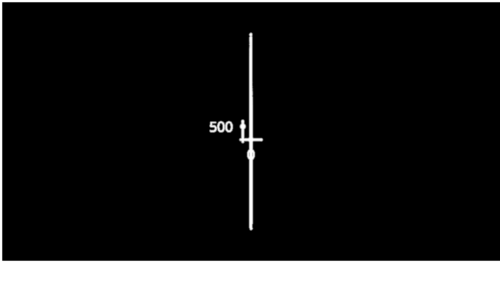

In [44]:
fig_s = fpl.Figure()

corr_scatter = fig_s[0, 0].add_scatter(np.column_stack([corrs, errs]), sizes=2, colors=(1, 1, 1, 0.5))

fig_s.show()

In [ ]:
plt.hist()

In [140]:
fig_s[0, 0].axes.y.tick_format = "0.6g"

In [118]:
fig_s[0, 0].axes.colors = ("r", "r", "r")

In [80]:
ix = np.argmin(np.linalg.norm(np.column_stack([corrs, errs]) - np.column_stack([0.67, 110.8]), ord=2))

In [81]:
corrs[ix]

np.float64(1.0)

In [ ]:
@fig_s[0, 0].renderer.add_event_handler("click")
def on_click_point(ev):
    xy = fig_s[0, 0].map_screen_to_world(ev)

    min_corrs_ix = np.argmin(corrs - xy[0])
    min_errs_ix = np.argmin(errs - xy[1])

    corr_scatter.data[]

In [73]:
ix = np.argmin(corr_scatter.data[:, :-1] - np.column_stack([0.3, 110.8]))

In [74]:
ix

np.int64(4263802)

In [72]:
corrs[ix], errs[ix]

(np.float64(-0.028612022013627003), np.float64(110.88006189063147))

In [158]:
ixs = np.where((corrs > -10.0) & (corrs < 10.0) & (errs > 111) & (errs < 112.85))[0]
ixs

array([  1799,   1851, 465284])

In [159]:
p1, p2 = np.unravel_index(ixs[1], shape=(Y.shape[0], Y.shape[0]))
p1, p2

(np.int64(0), np.int64(1851))

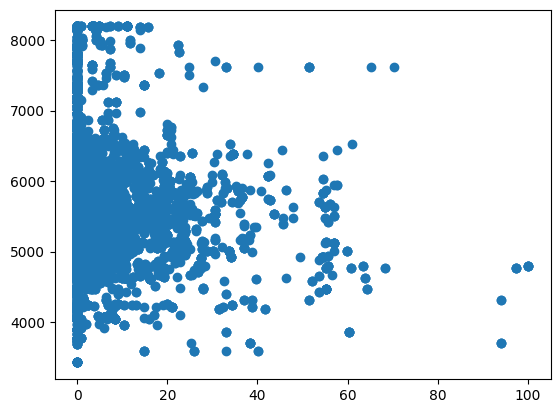

In [160]:
plt.scatter(Y[p1], Y[p2])

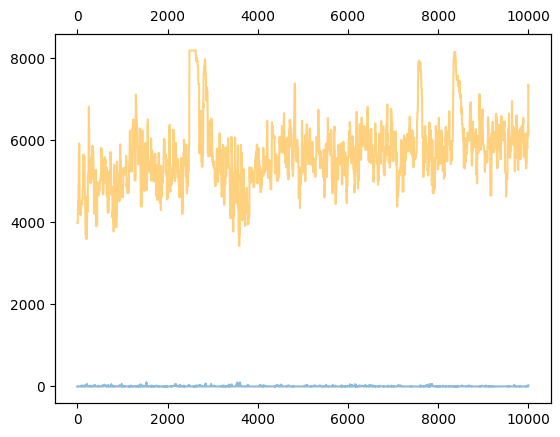

In [161]:
plt.plot(Y[p1], alpha=0.5)
plt.twiny()
plt.plot(Y[p2], alpha=0.5, c="orange")

In [163]:
selector_cov.selection = p2

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
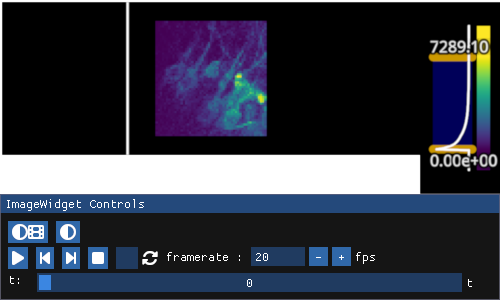

In [164]:
fpl.ImageWidget(movie, cmap="viridis").show()

In [165]:
scatter_point.data

VertexPositions buffer data:
array([[49., 34.,  0.]], dtype=float32)

In [23]:
corr_matrix.min(), corr_matrix.max()

(np.float64(110.84054131629962), np.float64(111.01038691900081))

In [21]:
scatter_point.colors = (1, 0, 0, 0.8)

In [22]:
iw.cmap = "viridis_r"

In [47]:
selector_cov.selection = i1

In [46]:
selector_cov.selection = i2

In [162]:
for g in iw.managed_graphics:
    g.vmin, g.vmax = -10, 10

In [10]:
B.min(), B.max()

(np.float32(0.0), np.float32(1.3595536))

In [ ]:
img = B[0].reshape(55, 53)

iw = fpl.ImageWidget(
    data=[B, img],
    cmap="viridis",
    names=["covariance", "row image"],
    figure_kwargs={"size": (700, 400), "controller_ids": [[0, 1]]}
)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = B.min(), B.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    iw.managed_graphics[1].data = B[ix].reshape(55, 53)


iw.show()